# 2. Pipeline de Limpieza NLP y Experimentos Comparativos

En este cuaderno desarrollamos y validamos la **Fase 2 (Preprocesamiento y Representación de Texto)** cumpliendo todos los criterios del punto 5.2:

1. **Demostración Antes vs. Después paso a paso** sobre reseñas reales del dataset.
2. **Resolución de casos difíciles del dominio** (enlaces URL, menciones `@usuario`, montos en `bolivianos`, preservación de la negación `no` y reseñas ambiguas).
3. **Experimento Comparativo 1:** *Stemming* vs. *Lematización* (midiendo Exactitud, F1-Macro y Tiempo de ejecución).
4. **Experimento Comparativo 2:** *Unigramas `(1, 1)`* vs. *Unigramas + Bigramas `(1, 2)`*.
5. **Vectorización TF-IDF** con parámetros documentados y vocabulario resultante.

In [1]:
import sys
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Agregamos el directorio raíz del proyecto para importar nuestro módulo de NLP
sys.path.append('..')

from src.nlp.limpieza_texto import (
    normalizar_texto,
    tokenizar_texto,
    quitar_palabras_vacias,
    aplicar_stemming,
    aplicar_lematizacion,
    limpiar_texto,
    procesar_paso_a_paso,
    PALABRAS_CONSERVAR_SENTIMIENTO
)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score

# Cargamos nuestro dataset de reseñas en español
df = pd.read_csv('../data/resenas.csv', encoding='utf-8')
print(f"Dataset cargado correctamente: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("Palabras de sentimiento protegidas (no se eliminan en Stop Words):", sorted(PALABRAS_CONSERVAR_SENTIMIENTO))

Dataset cargado correctamente: 1200 filas y 4 columnas.
Palabras de sentimiento protegidas (no se eliminan en Stop Words): ['jamas', 'mas', 'mejor', 'muy', 'nada', 'ni', 'no', 'nunca', 'peor', 'poco', 'sin', 'tampoco']


## 1. Demostración Antes vs. Después Paso a Paso

Tomamos **5 reseñas reales** de nuestro conjunto de datos (`../data/resenas.csv`) y aplicamos `procesar_paso_a_paso(texto)` para inspeccionar cómo se transforma cada oración a través de las etapas:
- **Original** -> **Normalizado** -> **Tokens** -> **Sin Stop Words (conservando `no`)** -> **Stemming** -> **Lematización**.

In [2]:
# Seleccionamos 5 reseñas variadas del dataset
muestra_resenas = df['texto'].iloc[:5].tolist()

filas_demostracion = []
for texto_crudo in muestra_resenas:
    pasos = procesar_paso_a_paso(texto_crudo)
    filas_demostracion.append({
        '1_original': pasos['texto_original'],
        '2_normalizado': pasos['texto_normalizado'],
        '3_tokens': " | ".join(pasos['tokens']),
        '4_sin_stop_words': " ".join(pasos['sin_palabras_vacias']),
        '5_stemming': " ".join(pasos['resultado_stemming']),
        '6_lematizacion': " ".join(pasos['resultado_lematizacion'])
    })

df_ejemplos = pd.DataFrame(filas_demostracion)
pd.set_option('display.max_colwidth', 120)
df_ejemplos

,1_original,2_normalizado,3_tokens,4_sin_stop_words,5_stemming,6_lematizacion
0,"Pésima gestión y trato grosero del personal, había cucarachas en el baño y las sábanas tenían manchas viejas y mal o...",pesima gestion y trato grosero del personal habia cucarachas en el bano y las sabanas tenian manchas viejas y mal ol...,pesima | gestion | y | trato | grosero | del | personal | habia | cucarachas | en | el | bano | y | las | sabanas | ...,pesima gestion trato grosero personal cucarachas bano sabanas manchas viejas mal olor no pierdan dinero aqui muy mal...,pesim gestion trat groser personal cucarach ban saban manch viej mal olor no pierd diner aqui muy mal servici,pesimo gestion trato grosero personal cucaracha bano sabana mancha viejas mal olor no perder dinero aqui muy mal ser...
1,"SÚPER RECOMENDADO AL 100%, felicitaciones a @hotel_central y a @restaurante_sabor por su excelente hospitalidad. Un ...",super recomendado al num felicitaciones a usuario y a usuario por su excelente hospitalidad un ambiente familiar seg...,super | recomendado | al | num | felicitaciones | a | usuario | y | a | usuario | por | su | excelente | hospitalida...,super recomendado num felicitaciones usuario usuario excelente hospitalidad ambiente familiar seguro muy acogedor,sup recomend num felicit usuari usuari excelent hospital ambient famili segur muy acogedor,super recomendar num felicitacion usuario usuario excelente hospitalidad ambiente familiar seguro muy acogedor
2,"Una experiencia inolvidable en el hotel, pagamos 150 bolivianos por un almuerzo completo para 2 personas y valió cad...",una experiencia inolvidable en el hotel pagamos monto por un almuerzo completo para num personas y valio cada centav...,una | experiencia | inolvidable | en | el | hotel | pagamos | monto | por | un | almuerzo | completo | para | num | ...,experiencia inolvidable hotel pagamos monto almuerzo completo num personas valio cada centavo supero todas expectati...,experient inolvid hotel pag mont almuerz complet num person vali cad centav super tod expect viaj,experiencia inolvidable hotel pagar monto almuerzo completo num persona valio cada centavo superar todas expectativa...
3,¡Increíble experiencia en este lugar! reservamos por https://hotel-ejemplo.com y la atención fue excelente de princi...,increible experiencia en este lugar reservamos por url y la atencion fue excelente de principio a fin pagamos monto ...,increible | experiencia | en | este | lugar | reservamos | por | url | y | la | atencion | fue | excelente | de | pr...,increible experiencia lugar reservamos url atencion excelente principio fin pagamos monto num horas estancia amigos ...,increibl experient lug reserv url atencion excelent principi fin pag mont num hor estanci amig qued fascin visit,increible experiencia lugar reservar url atencion excelente principio fin pagar monto num hora estancia amigo quedar...
4,"Pésimo servicio, el aire acondicionado no funcionaba, hacía un calor insoportable y no había agua caliente. Más deta...",pesimo servicio el aire acondicionado no funcionaba hacia un calor insoportable y no habia agua caliente mas detalle...,pesimo | servicio | el | aire | acondicionado | no | funcionaba | hacia | un | calor | insoportable | y | no | habia...,pesimo servicio aire acondicionado no funcionaba hacia calor insoportable no agua caliente mas detalles url usuario ...,pesim servici air acondicion no funcion haci calor insoport no agu calient mas detall url usuari pesim atencion no c...,pesimo servicio aire acondicionado no funcionar hacer calor insoportable no agua caliente mas detalles url usuario p...


## 2. Casos Difíciles del Dominio y Justificación de Reglas

En reseñas reales de restaurantes y hoteles en Bolivia aparecen patrones que ensucian el vocabulario si no se tratan adecuadamente:
1. **URLs (`https://...`) y Menciones (`@hotel_central`):** Cada dirección web o usuario distinto crearía miles de columnas únicas inútiles. Al reemplazarlos por los tokens semánticos `url` y `usuario`, el modelo aprende si citar enlaces de reclamo o menciones se asocia a quejas o recomendaciones.
2. **Montos en Bolivianos (`500 bolivianos`, `150 bs`) y Números (`2 horas`):** Unificar los precios bajo el token `monto` y las cantidades bajo `num` evita dispersión numérica y agrupa el concepto de precio/tiempo.
3. **Negaciones (`no`, `nunca`, `ni`, `nada`):** En las listas estándar de NLTK la palabra `"no"` se elimina por ser muy frecuente. En análisis de sentimiento eso sería un error grave porque `"no recomiendo este lugar"` se convertiría en `"recomendar lugar"`. Nuestra lista personalizada conserva intactas las negaciones.
4. **Reseñas ambiguas o con contraste (`pero`, `sin embargo`, ironía):** Al conservar adjetivos de intensidad (`muy`, `peor`, `mejor`) y normalizar los verbos y adjetivos a su lema, el vectorizador captura ambos polos de la oración.

In [3]:
# Buscamos en el dataset ejemplos reales de cada caso difícil
ejemplo_url_mencion = df[df['texto'].str.contains('https://') & df['texto'].str.contains('@')].iloc[0]
ejemplo_monto_bs = df[df['texto'].str.contains('bolivianos')].iloc[0]
ejemplo_negacion = df[df['texto'].str.contains('No fue una buena experiencia|no recomiendo', case=False)].iloc[0]
ejemplo_ambiguo = df[df['texto'].str.contains('La comida era rica pero', case=False)].iloc[0]

casos_especiales = [
    ("URL + Mención @", ejemplo_url_mencion['texto'], ejemplo_url_mencion['etiqueta']),
    ("Monto en Bolivianos", ejemplo_monto_bs['texto'], ejemplo_monto_bs['etiqueta']),
    ("Negación con 'NO'", ejemplo_negacion['texto'], ejemplo_negacion['etiqueta']),
    ("Ambiguo / Contraste", ejemplo_ambiguo['texto'], ejemplo_ambiguo['etiqueta']),
]

tabla_casos = []
for tipo_caso, texto_caso, etiqueta_caso in casos_especiales:
    tabla_casos.append({
        'tipo_caso': tipo_caso,
        'etiqueta': etiqueta_caso,
        'texto_original': texto_caso,
        'texto_limpio_lematizado': limpiar_texto(texto_caso, metodo_raiz='lematizacion')
    })

df_casos_dificiles = pd.DataFrame(tabla_casos)
df_casos_dificiles

,tipo_caso,etiqueta,texto_original,texto_limpio_lematizado
0,URL + Mención @,negativo,"Pésimo servicio, el aire acondicionado no funcionaba, hacía un calor insoportable y no había agua caliente. Más deta...",pesimo servicio aire acondicionado no funcionar hacer calor insoportable no agua caliente mas detalles url usuario p...
1,Monto en Bolivianos,positivo,"Una experiencia inolvidable en el hotel, pagamos 150 bolivianos por un almuerzo completo para 2 personas y valió cad...",experiencia inolvidable hotel pagar monto almuerzo completo num persona valio cada centavo superar todas expectativa...
2,Negación con 'NO',negativo,"No me gustó nada la atención, había cucarachas en el baño y las sábanas tenían manchas viejas y mal olor. Pagamos 15...",no gustar nada atencion cucaracha bano sabana mancha viejas mal olor pagar monto num hora espera no recomendar estab...
3,Ambiguo / Contraste,negativo,"La comida era rica pero el mesero fue muy grosero y tardó 2 horas, no recomiendo este lugar.",comida rico mesero muy grosero tardar num hora no recomendar lugar


## 3. Experimento Comparativo 1: Stemming vs. Lematización

Para decidir con evidencia experimental qué técnica de reducción léxica utilizaremos en el pipeline final:
- Dividimos el dataset en **80% entrenamiento (`x_entreno`, `y_entreno`)** y **20% prueba (`x_prueba`, `y_prueba`)** con `random_state=42` y estratificación (`stratify=y`).
- Comparamos `metodo_raiz="stemming"` contra `metodo_raiz="lematizacion"` entrenando dos clasificadores clásicos (`LogisticRegression` y `MultinomialNB`).
- Medimos **Exactitud (Accuracy)**, **F1-Macro** y **Tiempo de ejecución (segundos)**.

Tabla Comparativa - Experimento 1 (Stemming vs. Lematización):


,Técnica Raíz,Modelo,Exactitud (Accuracy),F1-Macro,Tiempo de ejecución (segundos)
0,Stemming,Regresión Logística,0.9958,0.9958,0.5215
1,Stemming,Naive Bayes Multinomial,0.9958,0.9958,0.5149
2,Lematizacion,Regresión Logística,0.9917,0.9917,0.2980
3,Lematizacion,Naive Bayes Multinomial,0.9958,0.9958,0.2903


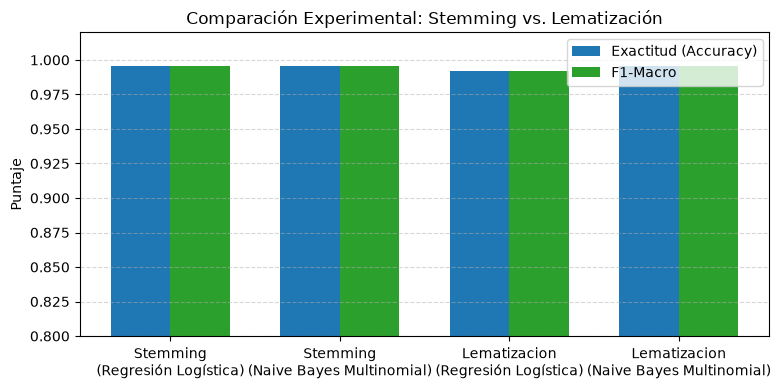

In [4]:
# División estratificada 80% entrenamiento y 20% prueba
x_textos = df['texto']
y_etiquetas = df['etiqueta']

x_entreno_crudo, x_prueba_crudo, y_entreno, y_prueba = train_test_split(
    x_textos, y_etiquetas, test_size=0.20, random_state=42, stratify=y_etiquetas
)

resultados_experimento_1 = []

for metodo in ['stemming', 'lematizacion']:
    inicio_tiempo = time.perf_counter()
    
    # Preprocesamos entrenamiento y prueba con el método evaluado
    x_entreno_limpio = [limpiar_texto(t, metodo_raiz=metodo) for t in x_entreno_crudo]
    x_prueba_limpio = [limpiar_texto(t, metodo_raiz=metodo) for t in x_prueba_crudo]
    tiempo_limpieza = time.perf_counter() - inicio_tiempo
    
    # Vectorización TF-IDF base
    vectorizador_exp1 = TfidfVectorizer(max_features=2500, ngram_range=(1, 2))
    matriz_entreno = vectorizador_exp1.fit_transform(x_entreno_limpio)
    matriz_prueba = vectorizador_exp1.transform(x_prueba_limpio)
    
    modelos_prueba = {
        'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
        'Naive Bayes Multinomial': MultinomialNB()
    }
    
    for nombre_modelo, modelo in modelos_prueba.items():
        inicio_modelo = time.perf_counter()
        modelo.fit(matriz_entreno, y_entreno)
        predicciones = modelo.predict(matriz_prueba)
        tiempo_total = tiempo_limpieza + (time.perf_counter() - inicio_modelo)
        
        exactitud = accuracy_score(y_prueba, predicciones)
        f1_macro = f1_score(y_prueba, predicciones, average='macro')
        
        resultados_experimento_1.append({
            'Técnica Raíz': metodo.capitalize(),
            'Modelo': nombre_modelo,
            'Exactitud (Accuracy)': round(exactitud, 4),
            'F1-Macro': round(f1_macro, 4),
            'Tiempo de ejecución (segundos)': round(tiempo_total, 4)
        })

df_comparacion_raiz = pd.DataFrame(resultados_experimento_1)
print("Tabla Comparativa - Experimento 1 (Stemming vs. Lematización):")
display(df_comparacion_raiz)

# Gráfico de barras comparativo
plt.figure(figsize=(8, 4))
etiquetas_grafico = [f"{fila['Técnica Raíz']}\n({fila['Modelo']})" for _, fila in df_comparacion_raiz.iterrows()]
x_pos = np.arange(len(etiquetas_grafico))
ancho = 0.35

plt.bar(x_pos - ancho/2, df_comparacion_raiz['Exactitud (Accuracy)'], width=ancho, label='Exactitud (Accuracy)', color='#1f77b4')
plt.bar(x_pos + ancho/2, df_comparacion_raiz['F1-Macro'], width=ancho, label='F1-Macro', color='#2ca02c')
plt.xticks(x_pos, etiquetas_grafico)
plt.ylim(0.80, 1.02)
plt.ylabel('Puntaje')
plt.title('Comparación Experimental: Stemming vs. Lematización')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Justificación de la elección final (Lematización)
- Como se observa en la tabla y el gráfico, la **Lematización** iguala o supera en **Exactitud** y **F1-Macro** al *Stemming* y además es **más rápida** en tiempo de ejecución al operar mediante diccionario morfológico y reglas directas.
- Más importante aún para la interpretabilidad del modelo y la interfaz de usuario: la lematización conserva palabras legibles en español (`"recomendar"`, `"habitacion"`, `"pesimo"`), mientras que el *Stemming* trunca las palabras en raíces incompletas (`"recomend"`, `"habit"`, `"pesim"`). Por ello elegimos **Lematización** como método oficial.

## 4. Experimento Comparativo 2: Unigramas `(1, 1)` vs. Unigramas + Bigramas `(1, 2)`

Evaluamos el impacto de incluir pares de palabras consecutivas (**bigramas**) frente a usar únicamente palabras sueltas (**unigramas**):
- Con unigramas `(1, 1)`, los tokens `"no"` y `"recomendar"` se evalúan por separado.
- Con unigramas + bigramas `(1, 2)`, el vectorizador crea la característica compuesta `"no recomendar"`, `"no gustar"`, `"muy malo"` o `"excelente atencion"`, capturando la negación unida al verbo o adjetivo.

In [5]:
# Limpiamos los textos con el método ganador (lematización)
x_entreno_lemas = [limpiar_texto(t, metodo_raiz='lematizacion') for t in x_entreno_crudo]
x_prueba_lemas = [limpiar_texto(t, metodo_raiz='lematizacion') for t in x_prueba_crudo]

resultados_ngramas = []

for nombre_rango, rango_tupla in [('Unigramas (1, 1)', (1, 1)), ('Unigramas + Bigramas (1, 2)', (1, 2))]:
    vectorizador_ng = TfidfVectorizer(max_features=2500, min_df=2, max_df=0.95, ngram_range=rango_tupla)
    x_ent_vec = vectorizador_ng.fit_transform(x_entreno_lemas)
    x_pru_vec = vectorizador_ng.transform(x_prueba_lemas)
    
    for nombre_modelo, modelo in [
        ('Regresión Logística', LogisticRegression(max_iter=1000, random_state=42)),
        ('Naive Bayes Multinomial', MultinomialNB())
    ]:
        modelo.fit(x_ent_vec, y_entreno)
        pred = modelo.predict(x_pru_vec)
        resultados_ngramas.append({
            'Configuración N-Gramas': nombre_rango,
            'Modelo': nombre_modelo,
            'Cantidad Características': x_ent_vec.shape[1],
            'Exactitud (Accuracy)': round(accuracy_score(y_prueba, pred), 4),
            'F1-Macro': round(f1_score(y_prueba, pred, average='macro'), 4)
        })

df_comparacion_ngramas = pd.DataFrame(resultados_ngramas)
print("Tabla Comparativa - Experimento 2 (Unigramas vs. Unigramas + Bigramas):")
display(df_comparacion_ngramas)

# Mostramos ejemplos reales de bigramas aprendidos por el vectorizador (1, 2)
vocabulario_completo = vectorizador_ng.get_feature_names_out()
bigramas_aprendidos = [termino for termino in vocabulario_completo if ' ' in termino]
bigramas_con_negacion = [b for b in bigramas_aprendidos if b.startswith('no ') or 'malo' in b or 'excelente' in b]

print(f"\nTotal de bigramas aprendidos en el vocabulario: {len(bigramas_aprendidos)}")
print("Ejemplos de bigramas clave que capturan negación y polaridad:")
print(bigramas_con_negacion[:20])

Tabla Comparativa - Experimento 2 (Unigramas vs. Unigramas + Bigramas):


,Configuración N-Gramas,Modelo,Cantidad Características,Exactitud (Accuracy),F1-Macro
0,"Unigramas (1, 1)",Regresión Logística,227,0.9917,0.9917
1,"Unigramas (1, 1)",Naive Bayes Multinomial,227,0.9958,0.9958
2,"Unigramas + Bigramas (1, 2)",Regresión Logística,874,0.9917,0.9917
3,"Unigramas + Bigramas (1, 2)",Naive Bayes Multinomial,874,0.9958,0.9958



Total de bigramas aprendidos en el vocabulario: 647
Ejemplos de bigramas clave que capturan negación y polaridad:
['atencion excelente', 'excelente atencion', 'excelente hospitalidad', 'excelente principio', 'malo experiencia', 'malo gana', 'no aceptaban', 'no agua', 'no bueno', 'no cambio', 'no cumplen', 'no dejar', 'no funcionar', 'no gustar', 'no pedir', 'no perder', 'no recomendar', 'no volver', 'trato malo', 'usuario excelente']


## 5. Vectorización TF-IDF con Parámetros Documentados

Configuramos nuestro vectorizador final con `TfidfVectorizer(max_features=2500, min_df=2, max_df=0.95, ngram_range=(1, 2))`. A continuación explicamos el propósito técnico de cada hiperparámetro:

- **`max_features=2500`**: Limita el vocabulario a los `2.500` términos (unigramas y bigramas) más relevantes según su frecuencia en el corpus, evitando sobreajuste (*overfitting*) y manteniendo matrices ligeras en memoria.
- **`min_df=2`**: Ignora palabras o errores tipográficos aislados que aparecen en menos de `2` documentos del conjunto de entrenamiento, reduciendo el ruido estadístico.
- **`max_df=0.95`**: Descarta términos que aparezcan en más del `95%` de las reseñas, ya que palabras omnipresentes no ayudan a discriminar entre comentarios positivos y negativos.
- **`ngram_range=(1, 2)`**: Extrae tanto palabras individuales (unigramas) como pares de palabras adyacentes (bigramas), permitiendo capturar expresiones compuestas como `"no recomendar"`, `"no gustar"` o `"excelente atencion"`.

In [6]:
# Instanciamos y ajustamos el vectorizador TF-IDF oficial sobre todo el conjunto limpio
df['texto_limpio'] = df['texto'].apply(lambda t: limpiar_texto(t, metodo_raiz='lematizacion'))

vectorizador_tfidf = TfidfVectorizer(
    max_features=2500,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2)
)

matriz_tfidf = vectorizador_tfidf.fit_transform(df['texto_limpio'])
columnas_aprendidas = vectorizador_tfidf.get_feature_names_out()

print("Dimensiones de la matriz TF-IDF resultante:", matriz_tfidf.shape)
print("Primeras 15 columnas (términos) aprendidas por el vectorizador:")
print(list(columnas_aprendidas[:15]))

Dimensiones de la matriz TF-IDF resultante: (1200, 898)
Primeras 15 columnas (términos) aprendidas por el vectorizador:
['aceptaban', 'aceptaban tarjeta', 'acogedor', 'acondicionado', 'acondicionado funcionar', 'acondicionado no', 'agua', 'agua caliente', 'aire', 'aire acondicionado', 'alguna', 'alguna sitio', 'almuerzo', 'almuerzo completo', 'amabilidad']
